# Задача кредитного скоринга (Lending Club)

**Описание задачи:**
Бинарная классификация. По данным заявки на кредит нужно предсказать, вернет ли заемщик деньги (Fully Paid) или уйдет в дефолт (Charged Off). 

**Данные:** https://www.kaggle.com/datasets/wordsforthewise/lending-club

**Метод:** Классификатор k-ближайших соседей (KNN), а также регрессия и Random Forest для сравнения.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set(style="whitegrid")
%matplotlib inline

## 1. Берем только нужные колонки и ограничиваем выборку, чтобы алгоритм работал быстрее.

In [14]:
PATH = r"C:\Users\veron\OneDrive\Рабочий стол\accepted_2007_to_2018Q4.csv.gz"
usecols = [
    "loan_amnt", "term", "int_rate", "installment", "grade", "sub_grade",
    "emp_length", "home_ownership", "annual_inc", "verification_status",
    "purpose", "dti", "delinq_2yrs", "open_acc", "pub_rec",
    "revol_util", "total_acc", "loan_status", "application_type"
]

df_full = pd.read_csv(PATH, usecols=usecols, low_memory=False)
df = df_full[df_full["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()
df["target"] = (df["loan_status"] == "Charged Off").astype(int) # 1 = дефолт
df = df.drop(columns=["loan_status"])

N_SAMPLE = 40_000
if len(df) > N_SAMPLE:
    df = df.sample(N_SAMPLE, random_state=RANDOM_STATE).reset_index(drop=True)
print("Размер данных после отбора:", df.shape)

Размер данных после отбора: (40000, 19)


## 2. Разбить данные на обучающую и тестовую выборки
Используем разделение на группы, чтобы сохранить баланс классов.

In [15]:
X = df.drop(columns=["target"])
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (30000, 18), Test: (10000, 18)


## 3. Визуализация и вычисление основных характеристик

,count,mean,std,min,25%,50%,75%,max
loan_amnt,30000.0,14435.530000,8770.526983,1000.00,7800.000,12000.00,20000.0000,40000.00
int_rate,30000.0,13.233586,4.794007,5.31,9.710,12.74,15.9900,30.99
installment,30000.0,438.821759,262.822296,28.82,247.205,375.04,585.7575,1719.83
annual_inc,30000.0,76214.994927,71920.341960,0.00,45590.000,65000.00,90000.0000,7000000.00
dti,29993.0,18.309804,11.443770,0.00,11.850,17.67,24.0000,999.00
revol_util,29980.0,52.015884,24.446505,0.00,33.600,52.50,70.8000,126.40
open_acc,30000.0,11.578167,5.473849,0.00,8.000,11.00,14.0000,90.00
total_acc,30000.0,24.873333,11.931408,2.00,16.000,23.00,32.0000,107.00
delinq_2yrs,30000.0,0.321267,0.884843,0.00,0.000,0.00,0.0000,26.00
pub_rec,30000.0,0.218600,0.571511,0.00,0.000,0.00,0.0000,10.00


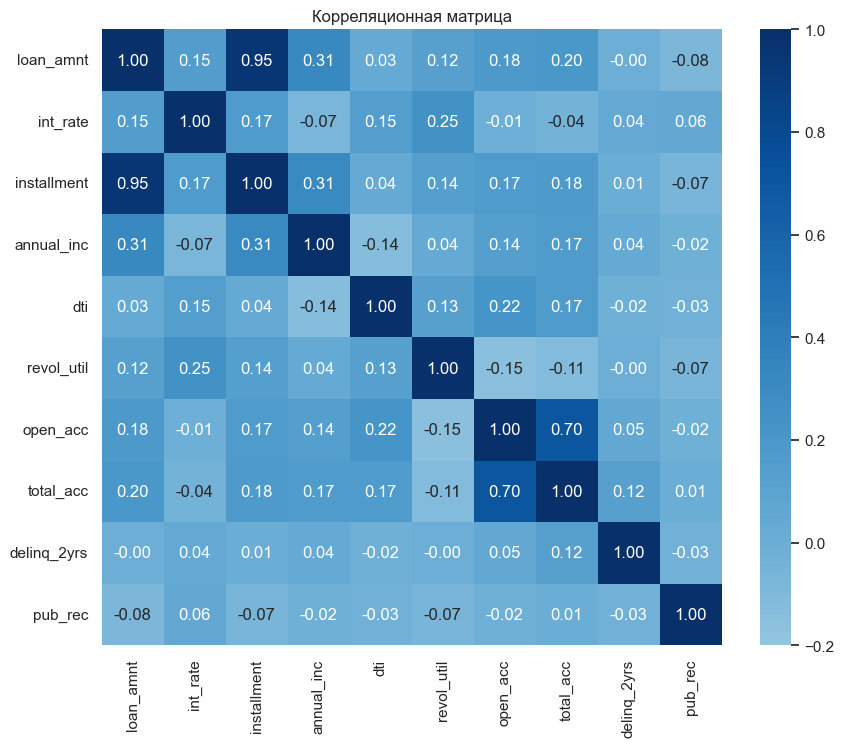

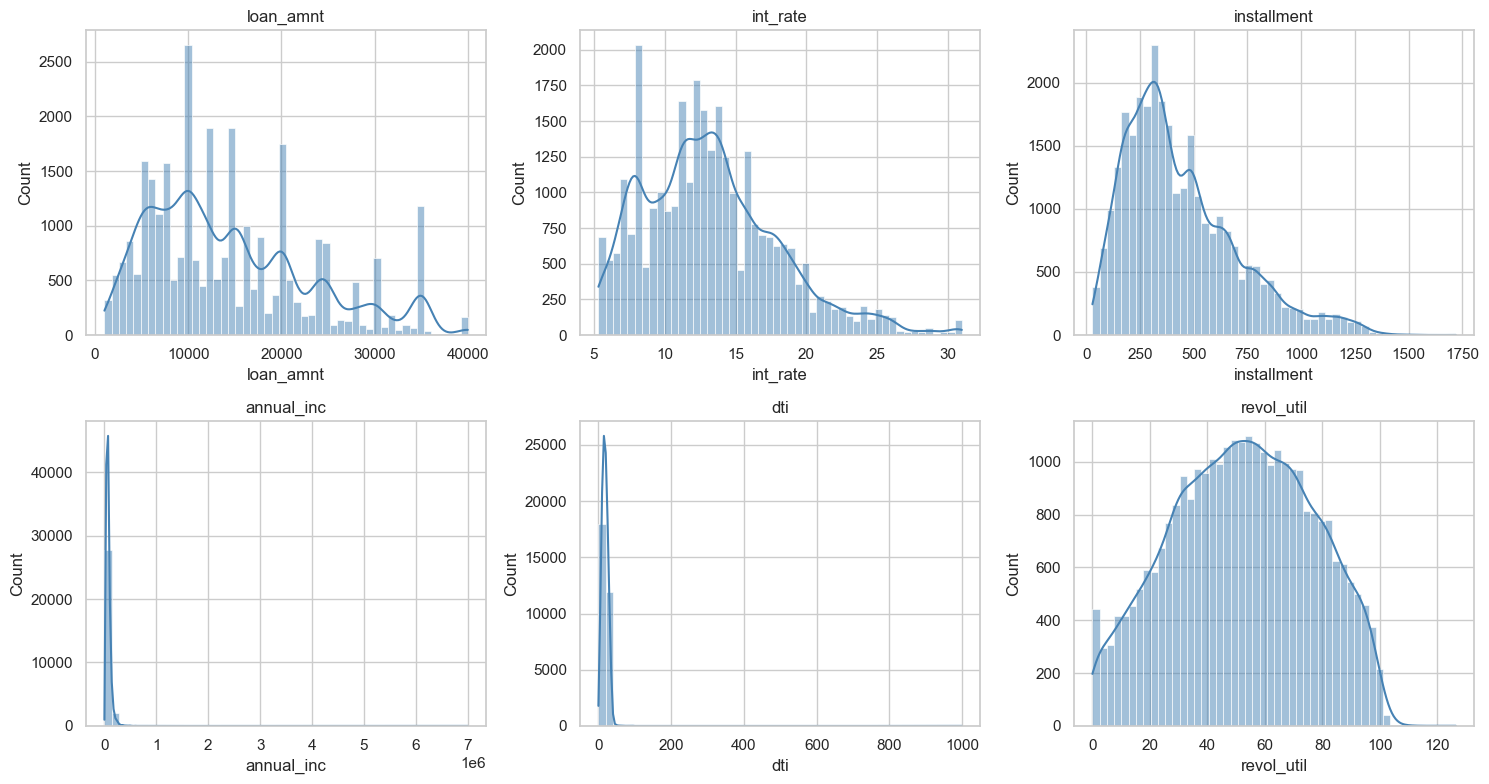

C:\Users\veron\AppData\Local\Temp\ipykernel_12676\1476934721.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y_train, palette="Blues")


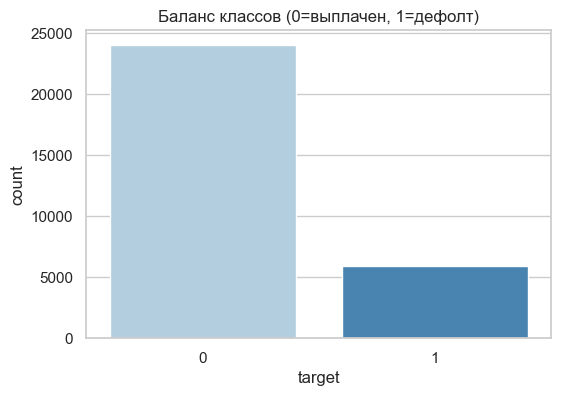

In [17]:
num_cols = ["loan_amnt", "int_rate", "installment", "annual_inc",
            "dti", "revol_util", "open_acc", "total_acc",
            "delinq_2yrs", "pub_rec"]

display(X_train[num_cols].describe().T)

# Корреляционная матрица
plt.figure(figsize=(10, 8))
sns.heatmap(X_train[num_cols].corr(), annot=True, fmt=".2f", 
            cmap="Blues", center=0, vmin=-0.2, vmax=1)
plt.title("Корреляционная матрица")
plt.show()

# Гистограммы распределений
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), num_cols[:6]):
    sns.histplot(X_train[col].dropna(), bins=50, ax=ax, kde=True, color='steelblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

# Баланс классов
plt.figure(figsize=(6, 4))
sns.countplot(x=y_train, palette="Blues")
plt.title("Баланс классов (0=выплачен, 1=дефолт)")
plt.show()

# Интерпретация
1. **Основные характеристики (таблица describe):**
   * `annual_inc` (годовой доход) имеет сильный разброс: от 0 до 7 000 000 (при среднем 76 000). Это говорит о наличии сильных выбросов.
   * `dti` (отношение долга к доходу) и `revol_util` (использование кредитных карт) имеют максимальные значения 999 и 126 соответственно, что также не совсем нормально.

2. **Корреляционная матрица:**
   * Наблюдается высокая положительная корреляция **0.95** между `loan_amnt` (суммой кредита) и `installment` (ежемесячным платежом). Чем больше кредит, тем больше платеж.
   * Также есть умеренная корреляция **0.70** между `open_acc` (открытые счета) и `total_acc` (всего счетов).
   * Остальные признаки показывают слабую корреляцию (близкую к 0).

3. **Распределения:**
   * `loan_amnt` имеет ступенчатый вид.
   * `int_rate` (процентная ставка) имеет бимодальное (двугорбое) распределение.
   * `annual_inc` и `dti` имеют ярко выраженный "правый хвост" (long-tail) — большинство значений сконцентрировано в начале шкалы, а редкие гигантские значения растягивают график вправо.

4. **Баланс классов:**
   * Наблюдается сильный дисбаланс: займов, которые были выплачены (класс 0), чем дефолтов (класс 1). 
   * **Вывод:** Использовать метрику `accuracy` (доля правильных ответов) нельзя, так как модель, которая всегда предсказывает "0". Нужно использовать `f1-score` и `confusion_matrix` (матрицу рассогласования).

## 4. Разобраться с выбросами
Обрезаем экстремальные значения в числовых признаках.

In [18]:
for col in ["annual_inc", "revol_util", "dti", "loan_amnt"]:
    hi = X_train[col].quantile(0.99)
    X_train[col] = X_train[col].clip(upper=hi)
    X_test[col] = X_test[col].clip(upper=hi)

## 5. Обработать пропущенные значения

In [19]:
for col in X_train.columns:
    fill = X_train[col].mode()[0] if X_train[col].dtype == "object" else X_train[col].median()
    X_train[col] = X_train[col].fillna(fill)
    X_test[col] = X_test[col].fillna(fill)

## 6. Обработать категориальные признаки

In [20]:
cat_cols = X_train.select_dtypes(include="object").columns.tolist()

if "term" in cat_cols:
    X_train["term"] = X_train["term"].str.extract(r"(\d+)").astype(int)
    X_test["term"] = X_test["term"].str.extract(r"(\d+)").astype(int)
    cat_cols.remove("term")

X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True)
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)
print("Размерность после One-Hot Encoding:", X_train.shape)

Размерность после One-Hot Encoding: (30000, 82)


## 7. Нормализация

In [21]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

## 8-9. Запуск KNN, подбор гиперпараметра и оценка
Ищем лучшее `k` с помощью GridSearchCV. Метрика — f1, так как классы несбалансированы.

In [25]:
param_grid = {"n_neighbors": [3, 5, 7, 11, 15, 21]}
gs = GridSearchCV(KNeighborsClassifier(), param_grid, cv=3, scoring="f1", n_jobs=-1)
gs.fit(X_train_sc, y_train)
print("Лучшее k:", gs.best_params_, " CV f1:", round(gs.best_score_, 4))

best_knn = gs.best_estimator_
y_pred_knn = best_knn.predict(X_test_sc)

print(f"KNN Train acc: {accuracy_score(y_train, best_knn.predict(X_train_sc)):.4f}")
print(f"KNN Test acc:  {accuracy_score(y_test, y_pred_knn):.4f}")
print(f"KNN Test f1:   {f1_score(y_test, y_pred_knn):.4f}")

print("\nМатрица рассогласования (kNN):")
print(confusion_matrix(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))

best_k = gs.best_params_['n_neighbors']
print(f"Оптимальное число соседей: {best_k}")

print("Анализ матрицы рассогласования")
print(f"Верно предсказанные выплаты (TN): 7187")
print(f"Верно предсказанные дефолты (TP): 406")
print(f"Ложные срабатывания (FP):         836 (банк зря отказал хорошим клиентам)")
print(f"Пропущенные дефолты (FN):         1571 (банк выдал кредит и потерял деньги)")

print("\nВывод по качеству классификатора")
print("1. Высокая Accuracy (0.76) обманчива: модель просто предсказывает класс большинства.")
print("2. Recall для дефолтов составляет всего 0.21 — модель находит 21% реальных дефолтов.")
print("3. F1-мера для дефолтов низкая (0.25).")
print("4. Для банка ошибка FN стоит дороже, чем FP.")

Лучшее k: {'n_neighbors': 3}  CV f1: 0.2368
KNN Train acc: 0.8538
KNN Test acc:  0.7593
KNN Test f1:   0.2523

Матрица рассогласования (kNN):
[[7187  836]
 [1571  406]]
              precision    recall  f1-score   support

           0       0.82      0.90      0.86      8023
           1       0.33      0.21      0.25      1977

    accuracy                           0.76     10000
   macro avg       0.57      0.55      0.55     10000
weighted avg       0.72      0.76      0.74     10000

Оптимальное число соседей: 3
Анализ матрицы рассогласования
Верно предсказанные выплаты (TN): 7187
Верно предсказанные дефолты (TP): 406
Ложные срабатывания (FP):         836 (банк зря отказал хорошим клиентам)
Пропущенные дефолты (FN):         1571 (банк выдал кредит и потерял деньги)

Вывод по качеству классификатора
1. Высокая Accuracy (0.76) обманчива: модель просто предсказывает класс большинства.
2. Recall для дефолтов составляет всего 0.21 — модель находит 21% реальных дефолтов.
3. F1-мера дл

## 8. Пояснения
Для решения задачи был выбран метод KNN по следующим причинам:
1. Алгоритм не строит сложных зависимостей, а ищет похожих заемщиков в исторических данных.
2. KNN не требует, чтобы признаки были распределены по определенному закону.
3. KNN хорошо улавливает нелинейные границы решений (например, если заемщики с определенным сочетанием дохода и рейтинга всегда уходят в дефолт).

KNN чувствителен к масштабу признаков, поэтому перед запуском была проведена нормализация. Также для поиска оптимального гиперпараметра использовался `GridSearchCV`. Метрикой качества выбрана `f1`, так как классы несбалансированы.

## 10-11. Другие классификаторы и убираем несбалансированность
Используем `class_weight='balanced'` для логистической регрессии и Random Forest.

In [26]:
lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(X_train_sc, y_train)
y_pred_lr = lr.predict(X_test_sc)
print("Logistic Regression Test acc:", round(accuracy_score(y_test, y_pred_lr), 4))

print("\nМатрица рассогласования (LR):")
print(confusion_matrix(y_test, y_pred_lr))

rf = RandomForestClassifier(n_estimators=200, max_depth=12, class_weight="balanced",
                            random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print("\nRandom Forest Test acc:", round(accuracy_score(y_test, y_pred_rf), 4))

print("\nМатрица рассогласования (RF):")
print(confusion_matrix(y_test, y_pred_rf))

Logistic Regression Test acc: 0.6413

Матрица рассогласования (LR):
[[5045 2978]
 [ 609 1368]]

Random Forest Test acc: 0.6854

Матрица рассогласования (RF):
[[5657 2366]
 [ 780 1197]]


## 12. Исключение коррелированных переменных
Ищем признаки с корреляцией > 0.85 и удаляем их

In [27]:
corr_abs = X_train.corr().abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
to_drop = [c for c in upper.columns if any(upper[c] > 0.85)]
print("Сильно коррелированные признаки:", to_drop)

if to_drop:
    X_tr2 = X_train.drop(columns=to_drop)
    X_te2 = X_test.drop(columns=to_drop)
    sc2 = StandardScaler().fit(X_tr2)
    knn2 = KNeighborsClassifier(n_neighbors=gs.best_params_["n_neighbors"])
    knn2.fit(sc2.transform(X_tr2), y_train)
    print("KNN без коррелированных Test acc:", round(accuracy_score(y_test, knn2.predict(sc2.transform(X_te2))), 4))

Сильно коррелированные признаки: ['installment']
KNN без коррелированных Test acc: 0.758


## 13. Общие выводы 
В ходе выполнения работы была решена задача бинарной классификации для датасета Lending Club. Можно сделать следующие выводы:

* Корреляционный анализ выявил, что сумма кредита и ежемесячный платеж имеют корреляцию 0.95. Удаление одного из этих признаков (или других с корреляцией >0.85) может упростить модель без потери качества.
* Была выявлена несбалансированность классов: дефолты составляют лишь около 20% выборки.
* KNN (k=3): Показал низкую эффективность в условиях дисбаланса. Хотя точность (Accuracy) составила 0.76. Recall для дефолтов составил всего 0.21, а F1-мера — 0.25. Модель пропустила 1571 реальный дефолт (False Negative). Для банка это может быть существенно, так как означает выдачу кредитов ненадежным клиентам.
* Логистическая регрессия и Random Forest: Использование параметра `class_weight='balanced'` (штраф за ошибку на миноритарном классе) позволило значительно улучшить метрику Recall для дефолтов. Random Forest показал хороший результат, так как он устойчив к выбросам, не требует нормализации и улавливает нелинейные взаимосвязи между признаками
